In [9]:
import numpy as np
import scipy.signal as signal
from scipy.interpolate import PchipInterpolator
import soundfile as sf
from scipy.io import wavfile
import random
import matplotlib.pyplot as plt

# Reproducibility: set a global seed and create a Generator
# Change SEED to any integer to reproduce different runs
SEED = 1
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
random.seed(SEED)

In [10]:
soundcard_fs = 48000  # Sampling rate of sound card these are generated for

In [11]:
def generate_filtered_pink_pulse(duration_ms=2000, fs=48000, band=(8000, 16000), rms=0.007, spectral_jitter_db=0, jitter_resolution_oct=0.25, rng=None):
    """
    Generate filtered pink noise pulse at final output level, scaled to a fixed RMS (`rms`)
    so pulses are equally loud regardless of their spectral profile.
    `spectral_jitter_db` > 0 adds a smooth random spectral profile on top of the pink spectrum:
    random gains at nodes spaced `jitter_resolution_oct` octaves apart, smoothly interpolated in
    log-frequency and scaled so the largest in-band deviation is +-`spectral_jitter_db` dB.
    Accepts an optional `rng` (numpy Generator). If `rng` is None the global `rng` is used.
    No additional scaling needed in Bonsai.
    """
    # Use provided RNG or fall back to global `rng` or new Generator
    if rng is None:
        try:
            rng = globals().get('rng', None)
            if rng is None:
                rng = np.random.default_rng()
        except Exception:
            rng = np.random.default_rng()

    # Duration in samples
    duration = int(round((duration_ms / 1000) * fs))

    # Smooth random gain profile (linear amplitude) over frequency, zero-mean in dB within the band
    def spectral_jitter(f):
        # Random nodes every `jitter_resolution_oct`, extending one node past each band edge
        lo = np.log2(band[0]) - jitter_resolution_oct
        hi = np.log2(band[1]) + jitter_resolution_oct
        nodes = np.arange(lo, hi + jitter_resolution_oct / 2, jitter_resolution_oct)
        # Profile is held flat beyond the band edges so out-of-band leakage is not boosted
        log_f = np.clip(np.log2(f), np.log2(band[0]), np.log2(band[1]))
        gains_db = PchipInterpolator(nodes, rng.uniform(-1, 1, len(nodes)))(log_f)
        in_band = (f >= band[0]) & (f <= band[1])
        gains_db -= gains_db[in_band].mean()
        gains_db *= spectral_jitter_db / np.max(np.abs(gains_db[in_band]))
        return 10 ** (gains_db / 20)

    # True pink noise (power ~ 1/f, -3 dB/octave): shape white noise in the frequency domain
    def pink_noise(n_samples):
        spectrum = np.fft.rfft(rng.standard_normal(n_samples))
        f = np.fft.rfftfreq(n_samples, d=1 / fs)
        f[0] = f[1]  # avoid divide-by-zero at DC
        spectrum /= np.sqrt(f)  # amplitude ~ 1/sqrt(f)  ->  power ~ 1/f
        if spectral_jitter_db > 0:
            spectrum *= spectral_jitter(f)
        return np.fft.irfft(spectrum, n_samples)

    pad = int(0.05 * fs)  # 50 ms lead-in so the bandpass filter has settled before the kept segment
    noise = pink_noise(duration + pad)

    # Bandpass filter design (4th-order Butterworth -> 8th-order bandpass, -3 dB at band edges)
    sos = signal.butter(4, band, btype='bandpass', fs=fs, output='sos')
    filtered = signal.sosfilt(sos, noise)

    # Drop the filter start-up transient, keep exact duration
    filtered = filtered[pad:]

    # Apply 16 ms sinusoidal ramp
    ramp_samples = int(0.016 * fs)
    ramp = np.sin(np.linspace(0, np.pi/2, ramp_samples))**2  # raised cosine ramp
    envelope = np.ones_like(filtered)
    envelope[:ramp_samples] *= ramp
    envelope[-ramp_samples:] *= ramp[::-1]
    shaped = filtered * envelope

    # Scale to final RMS (ready to use) - equal loudness regardless of spectral profile
    shaped *= rms / np.sqrt(np.mean(shaped**2))
    assert np.max(np.abs(shaped)) < 1, "Pulse would clip - lower `rms`"

    return shaped, fs


In [12]:
def generate_white_noise(duration_s=60, fs=48000, amplitude=0.1, rng=None):
    """
    Generate white noise at final output amplitude.
    Accepts an optional `rng` (numpy Generator). If `rng` is None the global `rng` is used.
    No additional scaling needed in Bonsai.
    """
    if rng is None:
        try:
            rng = globals().get('rng', None)
            if rng is None:
                rng = np.random.default_rng()
        except Exception:
            rng = np.random.default_rng()

    noise = rng.standard_normal(int(duration_s * fs))
    noise /= np.max(np.abs(noise))
    noise *= amplitude  # set final amplitude - no scaling needed in Bonsai
    return noise, fs



In [13]:
def generate_go_cue_wav(output_filename="go_cue.wav"):
    """
    Generate a WAV file with a 10 kHz pure tone for 0.1 seconds.
    
    Parameters:
    - output_filename: Name of the WAV file to create
    
    This generates the auditory Go cue as described in the paper:
    - Frequency: 10 kHz
    - Duration: 0.1 seconds
    """
    # Audio parameters
    frequency = 10000  # 10 kHz
    duration = 0.1     # 0.1 seconds
    sample_rate = 44100  # Standard audio sample rate
    amplitude = 0.9    # Volume (0.0 to 1.0) - using 0.9 for a strong signal
    
    # Generate time array
    t = np.linspace(0, duration, int(sample_rate * duration), False)
    
    # Generate tone (sine wave)
    tone = amplitude * np.sin(2 * np.pi * frequency * t)
    
    # Ensure the audio data is in the correct format for WAV files
    # Convert to 16-bit PCM
    tone_int16 = (tone * 32767).astype(np.int16)
    
    # Save as WAV file
    wavfile.write(output_filename, sample_rate, tone_int16)
    print(f"Go cue audio saved to {output_filename}")

# Generate the WAV file
if __name__ == "__main__":
    generate_go_cue_wav()


Go cue audio saved to go_cue.wav


In [14]:
def generate_8hz_pink_noise_train(total_duration_s=1.5, pulse_duration_ms=50, pulse_rate_hz=8, fs=44100, band=(8000,16000), rms=0.007, spectral_jitter_db=0, jitter_resolution_oct=0.25, rng=None):
    """
    Generate a pulse train of filtered pink pulses at `rate_hz` (default 8 Hz).

    - `pulse_duration_ms`: duration of each pulse in milliseconds (default 50 ms)
    - `total_duration_s`: total length of the output signal in seconds
    - One random pulse is generated per train and repeated for every pulse in it
      (frozen noise within a train; each call gives a new pulse, so trains differ).
    - `spectral_jitter_db` / `jitter_resolution_oct`: random spectral profile per train
      (see `generate_filtered_pink_pulse`). Each pulse has RMS `rms`.
    - Pulses have 16 ms sinusoidal onset/offset ramps (applied by
      `generate_filtered_pink_pulse`). Zeros are placed between pulses.

    Returns (signal, fs).
    """
    # Use provided RNG or fall back to global/default
    if rng is None:
        try:
            rng = globals().get('rng', None)
            if rng is None:
                rng = np.random.default_rng()
        except Exception:
            rng = np.random.default_rng()

    period_s = 1.0 / pulse_rate_hz
    period_samples = int(round(period_s * fs))
    total_samples = int(round(total_duration_s * fs))

    out = np.zeros(total_samples)
    n_periods = int(np.floor(total_duration_s * pulse_rate_hz))

    # Generate a single random pulse for this train (it applies its own 16 ms ramps)
    pulse, _ = generate_filtered_pink_pulse(duration_ms=pulse_duration_ms, fs=fs, band=band, rms=rms,
                                            spectral_jitter_db=spectral_jitter_db,
                                            jitter_resolution_oct=jitter_resolution_oct, rng=rng)
    pulse_samples = len(pulse)

    for i in range(n_periods):
        start = i * period_samples
        end = start + pulse_samples
        if start >= total_samples:
            break
        if end > total_samples:
            end = total_samples
            out[start:end] = pulse[: end - start]
        else:
            out[start:end] = pulse

    return out, fs


In [ ]:
if __name__ == "__main__":
    # Final pulse RMS levels, matched to the mean loudness of the previous peak-normalised (0.03) stimuli
    rms_50ms = 0.0069   # -43.2 dBFS
    rms_100ms = 0.0073  # -42.7 dBFS
    spectral_jitter_db = 10  # random spectral profile per train (+-10 dB, 1/4 octave resolution)

    # Generate filtered pink pulse (ready to use - no scaling needed)
    if 1:  # Replaced by pink_noise_train now
        pink_pulse, fs_pulse = generate_filtered_pink_pulse(
            duration_ms=50,
            band=(8000,16000),
            fs=soundcard_fs,
            rms=rms_50ms  # Final RMS for stimulus presentation
        )
        sf.write("filtered_pink_pulse.wav", pink_pulse, fs_pulse)
        print("Filtered pink pulse saved")

        pink_pulse_4Hz, fs_pulse_4Hz = generate_filtered_pink_pulse(
            duration_ms=100,
            band=(8000,16000),
            fs=soundcard_fs,
            rms=rms_100ms  # Final RMS for stimulus presentation
        )
        sf.write("filtered_pink_pulse_4Hz.wav", pink_pulse_4Hz, fs_pulse_4Hz)
        print("Filtered pink pulse 4Hz saved")
    #

    # Generate background white noise
    bg_noise, fs_noise = generate_white_noise(
        duration_s=60,
        fs=soundcard_fs,
        amplitude=0.03  # Final amplitude for background noise
    )
    sf.write("background_white_noise.wav", bg_noise, fs_noise)
    print("Background white noise saved")

    # Generate filtered pink pulse
    for i in range(100):
        pink_pulse_train, fs_pulse = generate_8hz_pink_noise_train(
            total_duration_s=1.5,
            pulse_duration_ms=50,
            pulse_rate_hz=8,
            fs=soundcard_fs,
            band=(8000,16000),
            rms=rms_50ms,  # Final RMS for stimulus presentation
            spectral_jitter_db=spectral_jitter_db
        )

        if i == 2:
            print(np.mean(np.abs(temp - pink_pulse_train)))
        #
        temp = pink_pulse_train
        sf.write(f"filtered_pink_pulse_train_{i}.wav", pink_pulse_train, fs_pulse)
        print("Filtered pink pulse train saved " + str(i))
    #

    # Generate filtered pink pulse
    for i in range(100):
        pink_pulse_train_4Hz, fs_pulse_4Hz = generate_8hz_pink_noise_train(
            total_duration_s=1.5,
            pulse_duration_ms=100,
            pulse_rate_hz=4,
            fs=soundcard_fs,
            band=(8000,16000),
            rms=rms_100ms,  # Final RMS for stimulus presentation
            spectral_jitter_db=spectral_jitter_db
        )
        sf.write(f"filtered_pink_pulse_train_4Hz_{i}.wav", pink_pulse_train_4Hz, fs_pulse_4Hz)
        print("Filtered pink pulse train 4Hz saved " + str(i))
    #
#

Filtered pink pulse saved
Filtered pink pulse 4Hz saved
Background white noise saved
Filtered pink pulse train saved 0
Filtered pink pulse train saved 1
0.002750193228317895
Filtered pink pulse train saved 2
Filtered pink pulse train saved 3
Filtered pink pulse train saved 4
Filtered pink pulse train saved 5
Filtered pink pulse train saved 6
Filtered pink pulse train saved 7
Filtered pink pulse train saved 8
Filtered pink pulse train saved 9
Filtered pink pulse train saved 10
Filtered pink pulse train saved 11
Filtered pink pulse train saved 12
Filtered pink pulse train saved 13
Filtered pink pulse train saved 14
Filtered pink pulse train saved 15
Filtered pink pulse train saved 16
Filtered pink pulse train saved 17
Filtered pink pulse train saved 18
Filtered pink pulse train saved 19
Filtered pink pulse train 4Hz saved 0
Filtered pink pulse train 4Hz saved 1
Filtered pink pulse train 4Hz saved 2
Filtered pink pulse train 4Hz saved 3
Filtered pink pulse train 4Hz saved 4
Filtered pink 

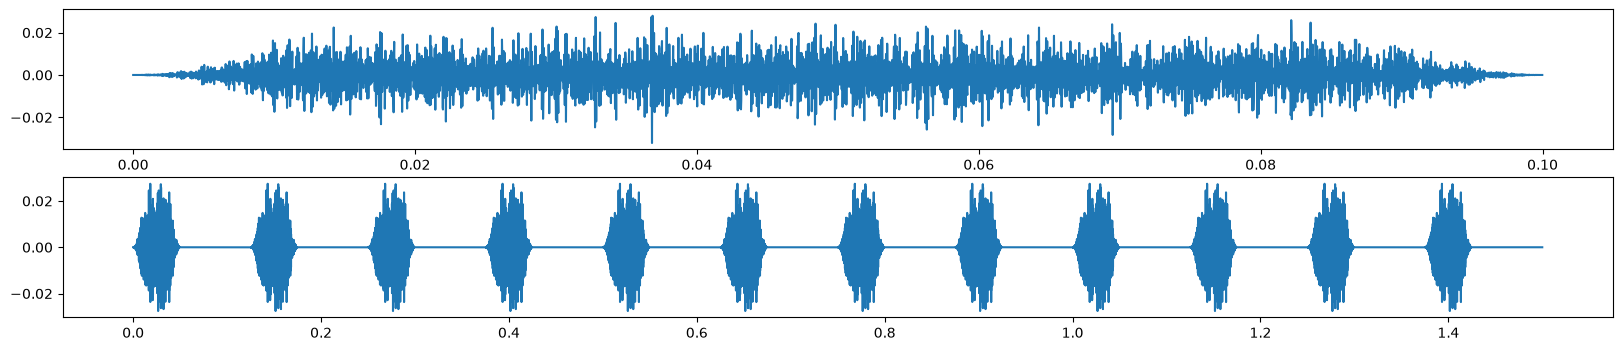

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(20, 4))
ax[0].plot(np.arange(len(pink_pulse_4Hz)) / soundcard_fs, pink_pulse_4Hz)
ax[1].plot(np.arange(len(pink_pulse_train)) / soundcard_fs, pink_pulse_train)
plt.show()